## Distribuição de Probabilidade

In [ ]:
# Livro de referência: Livro "Practical statistics for data scientists + 50+ essential concepts using R and Pyhton" - Bruce, Bruce & Gedeck

## Informações gerais

In [1]:
# erro estatístico - reflexo natural da variabilidade de uma determinada variável
# viés estatístico - é um erro sistemático, que empurra os dados em uma direção constantemente
    # viés de seleção - os dados que "sobreviveram"; a análise não considera dados amplos
    # seleção de autoviés - a análise é feita por extremos; ex: a análise de comentários de restaurantes onde só quem detestou a comida escreveu algo
    # data snooping - "tortura de dados", padrões e respostas que os analistas encontram após análise extensiva dos dados

In [2]:
# regressão à média
# fênomeno estatístico em que as amostras tendem a retornar ao resultado médio, porém este resultado costuma ser mascarado por intervenções externas
# ex: o chefe que interviu nos resultados de uma equipe que baixaram em um mês e no mês seguinte retornam à média histórica

In [3]:
# amostragem aleatória
# processo de seleção estruturado de forma a que nenhum subgrupo da população seja excluído durante as análises
# visa eliminar o erro de viés estatístico, mantendo somente erros aleatórios
# ex: em uma pesquisa eleitoral, é importante manter os diversos subgrupos que representam a sociedade, de forma a que não haja enviesamento em função de
# identificação com campo político

In [4]:
# amostragem estratificada
# seleção de amostra por subgrupo para entender o comportamento e representatividade de cada um
# ex: subgrupo por gênero, idade etc em uma pesquisa eleitoral

In [5]:
# distribuição de dados - como os valores individuais se distribuem
# distribuição amostral de uma estatística - distribuição obtida caso se calculasse uma estatística em amostras diferentes dentro da mesma população
    # ex: calcular a média salarial em grupos de 50 pessoas dentro de uma mesma população
# a distribuição amostral tende a ser mais estreita - é mais estável
# tende a ser mais normal (em formato de sino) do que os dados originais - Teora Central do Limite
# quanto maior a amostra, mais estreita e normal ela fica

In [6]:
# Erro padrão
# medida que captura a variabilidade da distribuição amostral
# tecnicamente, é o desvio padrão da distribuição amostral de uma estatística
# se eu repetir o cálculo da estatística em amostras diferentes do mesmo tamanho extraído da mesma população, a variabilidade gira em torno de um valor
# populacional, com desvio padrão; esse é o desvio padrão
# quando maior o tamanho da amostra, menor o erro padrão
# SE = desvio padrão / raiz da amostra

In [7]:
# importações
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import math

In [8]:
jobs = pd.read_csv("jobs_in_data_2024.csv",sep=",")

In [9]:
# Reconhecimento inicial
jobs.shape
jobs.info()
jobs.head()
jobs.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14199 entries, 0 to 14198
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           14199 non-null  int64 
 1   experience_level    14199 non-null  object
 2   employment_type     14199 non-null  object
 3   job_title           14199 non-null  object
 4   salary              14199 non-null  int64 
 5   salary_currency     14199 non-null  object
 6   salary_in_usd       14199 non-null  int64 
 7   employee_residence  14199 non-null  object
 8   work_setting        14199 non-null  object
 9   company_location    14199 non-null  object
 10  company_size        14199 non-null  object
 11  job_category        14199 non-null  object
dtypes: int64(3), object(9)
memory usage: 1.3+ MB


,work_year,salary,salary_in_usd
count,14199.000000,14199.000000,14199.00000
mean,2023.110501,149057.514262,149472.04944
std,0.686929,64932.044143,64379.26016
min,2020.000000,14000.000000,15000.00000
25%,2023.000000,102150.000000,104000.00000
50%,2023.000000,142000.000000,142000.00000
75%,2024.000000,185900.000000,185900.00000
max,2024.000000,450000.000000,450000.00000


In [10]:
# Reconhecimento inicial
jobs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14199 entries, 0 to 14198
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           14199 non-null  int64 
 1   experience_level    14199 non-null  object
 2   employment_type     14199 non-null  object
 3   job_title           14199 non-null  object
 4   salary              14199 non-null  int64 
 5   salary_currency     14199 non-null  object
 6   salary_in_usd       14199 non-null  int64 
 7   employee_residence  14199 non-null  object
 8   work_setting        14199 non-null  object
 9   company_location    14199 non-null  object
 10  company_size        14199 non-null  object
 11  job_category        14199 non-null  object
dtypes: int64(3), object(9)
memory usage: 1.3+ MB


In [11]:
# Reconhecimento inicial
jobs.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,work_setting,company_location,company_size,job_category
0,2024,Entry-level,Freelance,Applied Data Scientist,30000,USD,30000,United Kingdom,Remote,United Kingdom,M,Data Science and Research
1,2024,Executive,Full-time,Business Intelligence,230000,USD,230000,United States,In-person,United States,M,BI and Visualization
2,2024,Executive,Full-time,Business Intelligence,176900,USD,176900,United States,In-person,United States,M,BI and Visualization
3,2024,Senior,Full-time,Data Architect,171210,USD,171210,Canada,In-person,Canada,M,Data Architecture and Modeling
4,2024,Senior,Full-time,Data Architect,92190,USD,92190,Canada,In-person,Canada,M,Data Architecture and Modeling


In [12]:
# Reconhecimento inicial
jobs["salary"].describe()

count     14199.000000
mean     149057.514262
std       64932.044143
min       14000.000000
25%      102150.000000
50%      142000.000000
75%      185900.000000
max      450000.000000
Name: salary, dtype: float64

In [13]:
# erro padrão
# desvio padrão da amostra / raiz do tamanho da amostra
jobs["salary"].std() / np.sqrt(len(jobs["salary"]))

544.9167975620591

In [14]:
# intervalo de confiança
# forma de lidar com a variabilidade de uma amostragem
# ex: com 95% de confiança, a MÉDIA SALARIAL DA POPULAÇÃO de DS está entre $148.413 e $150.531
# Importante: a leitura correta é que se repetirmos a amostragem 100 vezes e construirmos o IC em cada uma,
#     aprox. 95 desses intervalos vão conter a verdadeira média populacional
# NÃO significa: há 95% de chance de a média estar nesse intervalo específico
# O intervalo ou contém a média verdadeira ou não contém — é 0 ou 1
# O 95% descreve o PROCEDIMENTO, não esse intervalo em particular

In [15]:
# Qualidade de dados é a fundação. Quantidade é o acabamento

In [16]:
# DISTRIBUIÇÃO ESTATÍSTICA

loans_income = pd.read_csv("loans_income.csv",sep=",") #banco de dados bruto
sample_data = pd.DataFrame({"income":loans_income["x"].sample(1000).squeeze(),"type":"Sampling data"}) #tomei amostragem aleatória de 
# 1000 amostras dentro da amostra principal

sample_mean_05 = pd.DataFrame({"income":[loans_income["x"].sample(5).mean() for _ in range (1000)],"type": "Mean of 5"}) #sample de 5 amostras 
# repetido 1000 vezes

sample_mean_20 = pd.DataFrame({"income":[loans_income["x"].sample(20).mean() for _ in range (1000)],"type":"Mean of 20"})

# Importante
# O _ é uma convenção do Python para dizer "preciso de uma variável de controle para o loop funcionar, 
# mas não vou usá-la em nenhum momento". É só um sinal para quem lê o código: "esse contador não importa, o que importa é a repetição"

results = pd.concat([sample_data,sample_mean_05,sample_mean_20]) #juntando todos os df de sample em um df só, para construção de gráficos

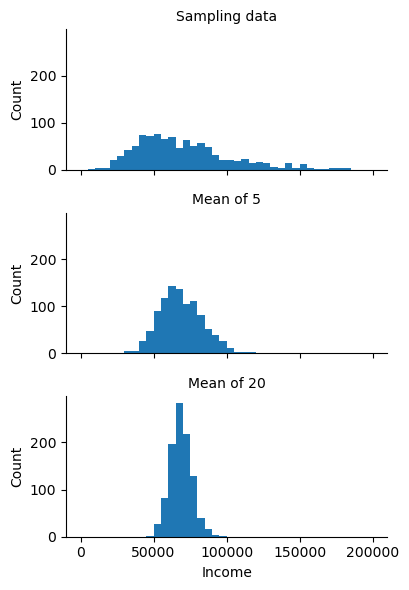

In [17]:
# gráfico para análise de distribuição amostral e distribuição estatística

g = sns.FacetGrid(results,col="type",col_wrap = 1, height = 2, aspect = 2)
g.map(plt.hist,"income",range = [0,200000], bins = 40)
g.set_axis_labels ("Income","Count")
g.set_titles("{col_name}")

In [18]:
# Teorema do Limite Central
# A distribuição das médias calculadas a partir de várias amostras (de uma amostra maior) terá a forma de uma curva normal (formato de sino), mesmo que a população não seja distribuída normalmente,
# desde que a amostra seja grande o suficiente
# O Teorema do Limite Central permite fórmulas para aproximação da distribuição normal, como a forma de distribuição-t

## Bootstrap

In [19]:
# Bootstrap
# técnica de reamostragem, onde as amostras usadas usam de reposição
# Não envolve a premissa de que os dados ou estatísticas amostrais possuam distribuição normal
# A amostra original é reamostrada várias vezes COM REPOSIÇÃO para estimar a distribuição amostral de uma estatística

# Algoritmo bootstrap
# 1- Tire uma reamostrage da amostra original COM REPOSIÇÃO, do mesmo tamanho
# 2- Calcule a estatística de interesse nessa reamostrage e grave
# 3- Repita os passos 1 e 2 R vezes (R arbitrário, tipicamente 1000 a 10000)
# 4- Use os R valores gravados para:
#    - calcular o erro padrão (std dos R valores)
#    - calcular o viés (média dos R valores - estatística original)
#    - construir intervalo de confiança (percentis 2.5% e 97.5%)
#    - plotar histograma para visualizar a distribuição amostral

In [20]:
# Bootstrap usando o método resample de scikit-learn
from sklearn.utils import resample
results = []
for nrepeat in range (1000):
    sample = resample(loans_income["x"])
    results.append(sample.median())
results = pd.Series(results)
print("Bootstrap Statistics:")
print(f"original: {loans_income['x'].median()}")
print(f"bias: {results.mean() - loans_income["x"].median()}") #mede o viés do amostrador
print(f"std. error: {results.std()}")

Bootstrap Statistics:
original: 62000.0
bias: -83.46949999999924
std. error: 227.2806642019275


In [21]:
# Resumo de bootstrap
# O que é — reamostrage com reposição para estimar a distribuição amostral de qualquer estatística sem premissa de normalidade.
# Como funciona — sorteia R amostras da original com reposição, calcula a estatística em cada uma, usa as R estatísticas para medir variabilidade.
# O que entrega — erro padrão, viés e intervalo de confiança do estimador.

In [22]:
results = []
for nrepeat in range (1000):
    sample = resample(jobs["salary"])
    results.append(sample.mean())
results = pd.Series(results)
print("Bootstrap Statistics:")
print(f"original: {jobs["salary"].mean()}")
print (f"bootstrap mean: {results.mean()}")
print(f"bias: {results.mean() - jobs["salary"].mean()}") #mede o viés do amostrador
print(f"std. error: {results.std()}")

Bootstrap Statistics:
original: 149057.5142615677
bootstrap mean: 149037.85685991973
bias: -19.65740164797171
std. error: 543.063268778383


In [23]:
jobs

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,work_setting,company_location,company_size,job_category
0,2024,Entry-level,Freelance,Applied Data Scientist,30000,USD,30000,United Kingdom,Remote,United Kingdom,M,Data Science and Research
1,2024,Executive,Full-time,Business Intelligence,230000,USD,230000,United States,In-person,United States,M,BI and Visualization
2,2024,Executive,Full-time,Business Intelligence,176900,USD,176900,United States,In-person,United States,M,BI and Visualization
3,2024,Senior,Full-time,Data Architect,171210,USD,171210,Canada,In-person,Canada,M,Data Architecture and Modeling
4,2024,Senior,Full-time,Data Architect,92190,USD,92190,Canada,In-person,Canada,M,Data Architecture and Modeling
...,...,...,...,...,...,...,...,...,...,...,...,...
14194,2021,Senior,Full-time,Data Specialist,165000,USD,165000,United States,Remote,United States,L,Data Management and Strategy
14195,2020,Senior,Full-time,Data Scientist,412000,USD,412000,United States,Remote,United States,L,Data Science and Research
14196,2021,Mid-level,Full-time,Principal Data Scientist,151000,USD,151000,United States,Remote,United States,L,Data Science and Research
14197,2020,Entry-level,Full-time,Data Scientist,105000,USD,105000,United States,Remote,United States,S,Data Science and Research


## Distribuição Normal

In [25]:
# Distribuição normal - os valores do eixo x são expressas em termos de desvios-padrão da média
# Parâmetros: média (em torno da qual todas as medidas se espalham) e desvio padrão (que diz quão espalhada é a distribuição)
# Erro - diferença entre um dado (ponto) e o valor previsto ou médio
# Padronizar - Subtrair a média e dividir pelo desvio padrão (z-score)
# z-score: o resultado de se padronizar um dado individual. Z = (x − μ) / σ
    # coloca tudo na mesma língua: desvio padrão
    # permite comparar resultados dentro de amostragens diferentes
# distribuição normal: uma distribuição com média = 0 e desvio padrão = 1
    # 68% dos dados caem dentro de μ ± 1σ
    # 95% dos dados caem dentro de μ ± 2σ
    # 99.7% dos dados caem dentro de μ ± 3σ
    # Regra empírica ou regra 68-95-99.7
# QQ-plot: um gráfico que mostra o que perto uma distribuição amostral é em relação a uma distribuição especial (e.g. a distribuição normal) # Teste de Ouro!!!!
# Fundamental: a normal é simétrica. Quando a variável não pode ser negativa, ou quando tem uma causa longa assimétrica,
# em geral é necessário realizar uma transformação logarítmica: se x não é normal, log(x) pode ser - distribuição log normal

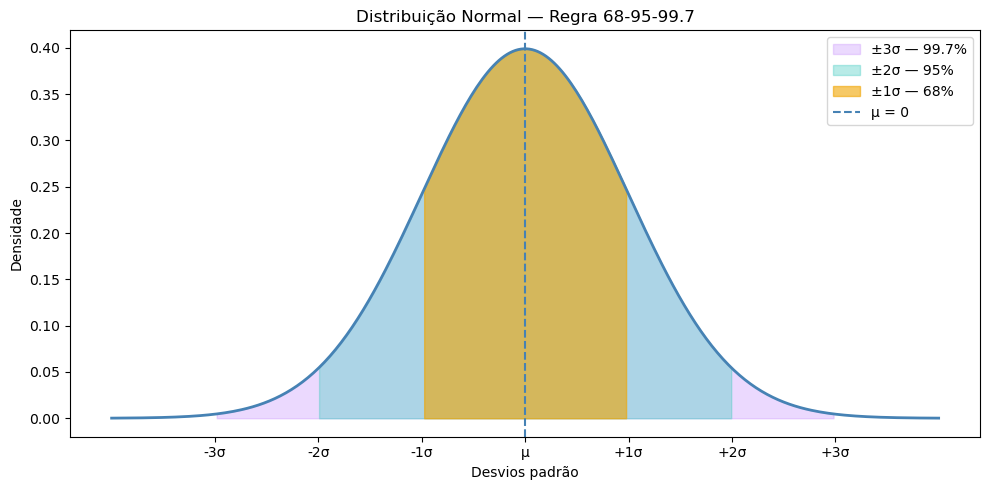

In [26]:
# Distribuição normal
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# normal padrão
x = np.linspace(-4, 4, 300)
y = stats.norm.pdf(x, 0, 1)

fig, ax = plt.subplots(figsize=(10, 5))

# curva completa
ax.plot(x, y, color="steelblue", linewidth=2)

# regiões — ordem do maior para o menor
ax.fill_between(x, y, where=(x >= -3) & (x <= 3),
                color="#c084fc", alpha=0.3, label="±3σ — 99.7%")
ax.fill_between(x, y, where=(x >= -2) & (x <= 2),
                color="#4ecdc4", alpha=0.4, label="±2σ — 95%")
ax.fill_between(x, y, where=(x >= -1) & (x <= 1),
                color="#f0a500", alpha=0.6, label="±1σ — 68%")

# linha da média
ax.axvline(0, color="steelblue", linewidth=1.5,
           linestyle="--", label="μ = 0")

# marcações no eixo x
ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
ax.set_xticklabels(["-3σ", "-2σ", "-1σ", "μ", "+1σ", "+2σ", "+3σ"])

ax.set_xlabel("Desvios padrão")
ax.set_ylabel("Densidade")
ax.set_title("Distribuição Normal — Regra 68-95-99.7")
ax.legend()
plt.tight_layout()
plt.show()

((array([-2.46203784, -2.12570747, -1.93122778, -1.79044653, -1.67819304,
         -1.58381122, -1.50174123, -1.42869743, -1.36256869, -1.30191411,
         -1.24570419, -1.19317644, -1.14374949, -1.09696931, -1.05247413,
         -1.00997067, -0.96921765, -0.93001393, -0.89218993, -0.85560121,
         -0.82012357, -0.78564937, -0.75208458, -0.71934648, -0.68736185,
         -0.65606548, -0.62539893, -0.59530962, -0.56574992, -0.53667655,
         -0.50804994, -0.47983378, -0.45199463, -0.42450149, -0.39732558,
         -0.37044003, -0.34381966, -0.31744076, -0.29128096, -0.26531902,
         -0.23953472, -0.21390872, -0.18842244, -0.16305799, -0.13779803,
         -0.1126257 , -0.08752455, -0.06247843, -0.03747145, -0.01248789,
          0.01248789,  0.03747145,  0.06247843,  0.08752455,  0.1126257 ,
          0.13779803,  0.16305799,  0.18842244,  0.21390872,  0.23953472,
          0.26531902,  0.29128096,  0.31744076,  0.34381966,  0.37044003,
          0.39732558,  0.42450149,  0.

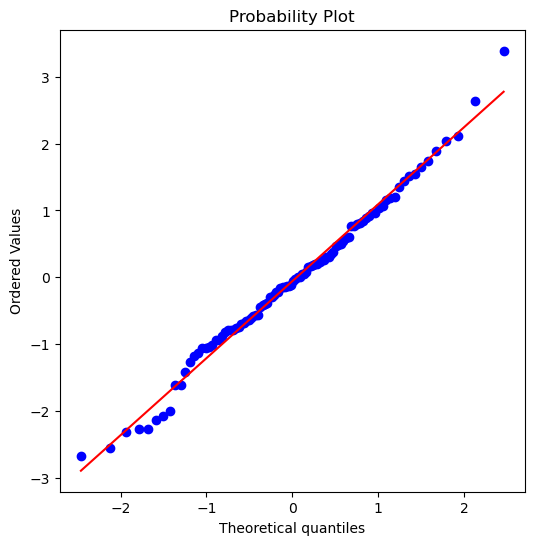

In [45]:
# QQ-plot usando o método scipy.stats.probplot

fig, ax = plt.subplots(figsize=(6,6))
norm_sample = stats.norm.rvs(size=100)
stats.probplot(norm_sample,plot=ax)

((array([-3.89640555, -3.67593223, -3.55510109, ...,  3.55510109,
          3.67593223,  3.89640555]),
  array([ 14000,  15000,  15000, ..., 448000, 450000, 450000], dtype=int64)),
 (64074.00386119124, 149057.5142615677, 0.9865631608062654))

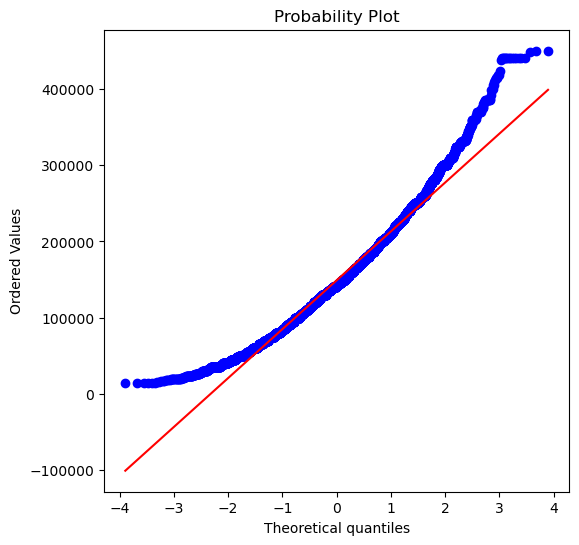

In [48]:
fig, ax = plt.subplots(figsize = (6,6))
stats.probplot(jobs["salary"],plot=ax)

((array([-3.89640555, -3.67593223, -3.55510109, ...,  3.55510109,
          3.67593223,  3.89640555]),
  array([ 9.54681261,  9.61580548,  9.61580548, ..., 13.01254851,
         13.01700286, 13.01700286])),
 (0.47730221009582924, 11.807001970375556, 0.9846413606884492))

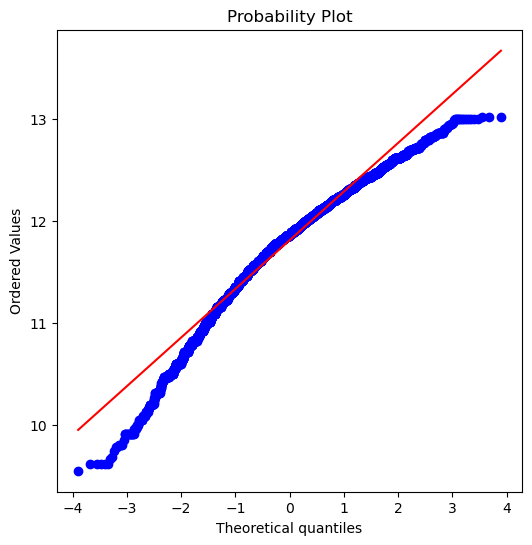

In [47]:
# transformação logarítmica
n_log = np.log(jobs["salary"])

# plotar QQ-plot
fig, ax = plt.subplots(figsize = (6,6))
stats.probplot(n_log,plot=ax)

0        10.308953
1        12.345835
2        12.083340
3        12.050646
4        11.431607
           ...    
14194    12.013701
14195    12.928779
14196    11.925035
14197    11.561716
14198    11.512925
Name: salary, Length: 14199, dtype: float64

In [49]:
teen_mental = pd.read_csv("Teen_Mental_Health_Dataset.csv",sep=",")

In [56]:
teen_mental["daily_social_media_hours"].describe()

count    1200.000000
mean        4.536667
std         2.029599
min         1.000000
25%         2.800000
50%         4.500000
75%         6.300000
max         8.000000
Name: daily_social_media_hours, dtype: float64

((array([-3.24978775, -2.98852082, -2.84297384, ...,  2.84297384,
          2.98852082,  3.24978775]),
  array([1., 1., 1., ..., 8., 8., 8.])),
 (1.9884413701533752, 4.536666666666668, 0.9778089285447285))

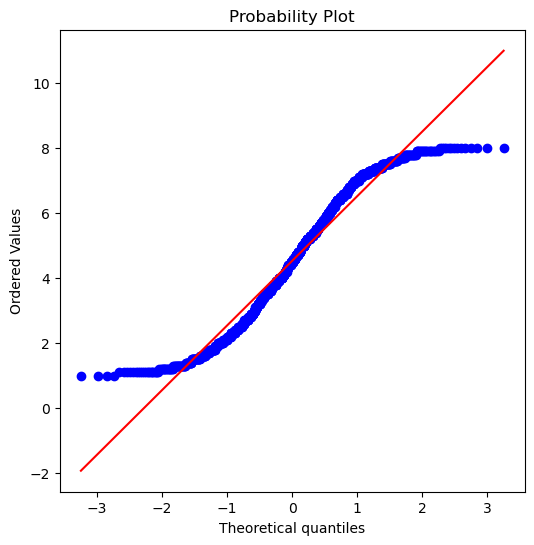

In [58]:
fig, ax = plt.subplots(figsize = (6,6))
stats.probplot(teen_mental["daily_social_media_hours"], plot = ax)

((array([-3.24978775, -2.98852082, -2.84297384, ...,  2.84297384,
          2.98852082,  3.24978775]),
  array([0.        , 0.        , 0.        , ..., 2.07944154, 2.07944154,
         2.07944154])),
 (0.5197577818634459, 1.3860919018116722, 0.9622745185122831))

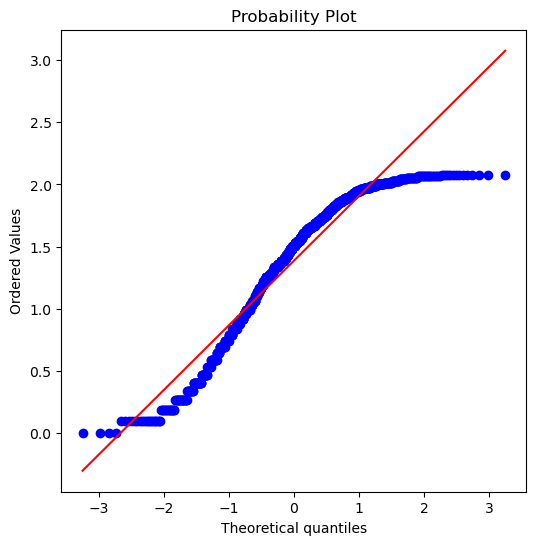

In [65]:
th_n_plot = np.log(teen_mental["daily_social_media_hours"])

fig,ax = plt.subplots(figsize = (6,6))
stats.probplot(th_n_plot, plot = ax)

0       2.066863
1       0.641854
2       0.262364
3       2.001480
4       1.547563
          ...   
1195    1.916923
1196    0.832909
1197    0.530628
1198    1.360977
1199    1.547563
Name: daily_social_media_hours, Length: 1200, dtype: float64

## Distribuição Cauda-Longa

In [95]:
# Distribuição de Cauda-Longa - descreve uma situação em que a maioria dos valores são (relativamente) pequenos, mas alguns valores são extraordinariamente grandes, e esses gigantes importam muito
# cauda: porção da curva onde valores relativamente extermos ocorrem a baixa frequência
# assimetria: onde uma das caudas é maior do que a outra
# as caudas correspondem a ambos extermos: pequeno e grande
# A maioria dos dados não é normal, e assumir uma distribuição norma, pode levar a subestimar valores extremos ("cisnes negros")

((array([-3.66693296, -3.43349504, -3.3049302 , ...,  3.3049302 ,
          3.43349504,  3.66693296]),
  array([-9.33142848, -3.7985726 , -3.06999973, ...,  3.63571546,
          4.13857274,  4.29285427])),
 (0.3141665090484467, 0.0056458357374863065, 0.7640314545417974))

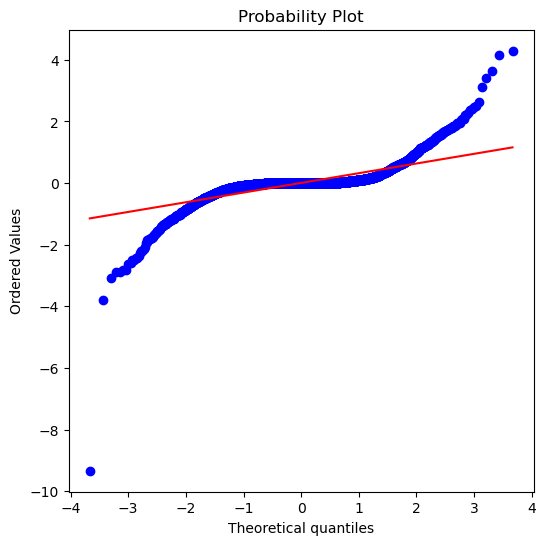

In [81]:
# estudo de caso: retorno diário das ações da NETFLIX

sp500_px = pd.read_csv("sp500_data.csv",sep=",")
nflx = sp500_px.NFLX
fix, ax = plt.subplots(figsize = (6,6))
stats.probplot(nflx,plot = ax)

# observe que os pontos ficam mais perto da linha normal entre -1 e +1 desvio-padrão, o que Tukey chama de "normal no meio" (eixo x)

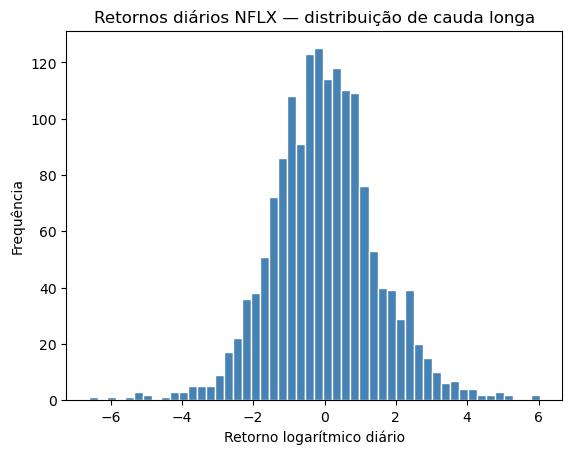

In [94]:
# calcula retornos diários
nflx = sp500_px["NFLX"]
nflx = nflx[nflx > 0]
nflx_retornos = pd.Series(np.diff(np.log(nflx)))

# histograma dos retornos
plt.hist(nflx_retornos, bins=50, edgecolor="white", color="steelblue")
plt.title("Retornos diários NFLX — distribuição de cauda longa")
plt.xlabel("Retorno logarítmico diário")
plt.ylabel("Frequência")
plt.show()

In [89]:
nflx.describe()

count    5647.000000
mean        0.005646
std         0.410986
min        -9.331428
25%        -0.021429
50%         0.000000
75%         0.020714
max         4.292854
Name: NFLX, dtype: float64

## Distribuição t-student

In [97]:
# utilizada quando se tem amostras pequenas
# possui forma semelhante à normal, porém com caudas mais pesadas, maiores, para se trabalhar com a incerteza própria da amostragem pequena
# parâmetro que controla o formato: graus de liberdade, que na prática é o número de amostras menos um (n-1)
    # quanto menor o n, mais conservadora a distribuição e maiores as caudas; quanto maior n, menores as causas e mais a t converge para a normal
    # para n = 30, é difícil distingur, a olho nu, a normal da t; com n=5 a diferença é enorme

In [ ]:
# o valor de desvio-padrão que captura 97,5% da distribuição varia em função dos graus de liberdade

In [100]:
from scipy import stats

for gl in [2, 5, 10, 20, 30, 100]:
    t_crit = stats.t.ppf(0.975, df=gl)
    print(f"gl={gl:>4}  →  t crítico = {t_crit:.4f}")

gl=   2  →  t crítico = 4.3027
gl=   5  →  t crítico = 2.5706
gl=  10  →  t crítico = 2.2281
gl=  20  →  t crítico = 2.0860
gl=  30  →  t crítico = 2.0423
gl= 100  →  t crítico = 1.9840


In [ ]:
# Quando usar? - em testagens estatísticas
    # Teste t para uma amostra
    # Teste t para duas amostras independentes
    # Coeficiente de regressão

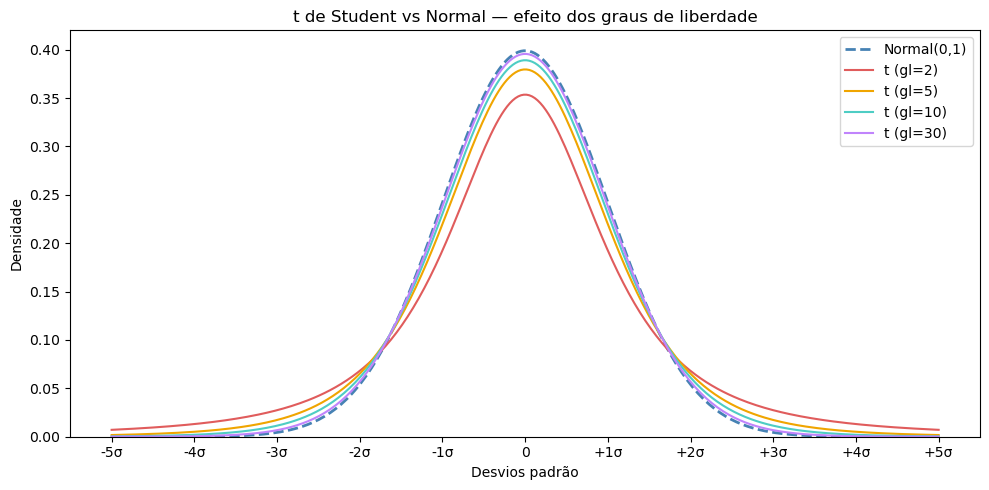

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

x = np.linspace(-5, 5, 300)

fig, ax = plt.subplots(figsize=(10, 5))

# normal padrão — referência
ax.plot(x, stats.norm.pdf(x), color="steelblue",
        linewidth=2, linestyle="--", label="Normal(0,1)")

# t com diferentes graus de liberdade
for gl, cor in [(2, "#e05c5c"), (5, "#f0a500"),
                (10, "#4ecdc4"), (30, "#c084fc")]:
    ax.plot(x, stats.t.pdf(x, df=gl), linewidth=1.5,
            color=cor, label=f"t (gl={gl})")

# eixo x com marcações explícitas incluindo -3,-2,-1,0,1,2,3
ax.set_xticks([-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5])
ax.set_xticklabels(["-5σ", "-4σ", "-3σ", "-2σ", "-1σ",
                    "0", "+1σ", "+2σ", "+3σ", "+4σ", "+5σ"])

ax.set_xlabel("Desvios padrão")
ax.set_ylabel("Densidade")
ax.set_title("t de Student vs Normal — efeito dos graus de liberdade")
ax.legend()
ax.set_ylim(0, 0.42)
plt.tight_layout()
plt.show()

In [ ]:
# A t de Student é a distribuição da honestidade intelectual.
# Ela diz: "com amostra pequena, você sabe menos do que pensa — e seu intervalo de confiança precisa refletir isso".
# À medida que você coleta mais dados, a t se torna cada vez mais parecida com a normal — a incerteza diminui organicamente com o tamanho da amostra
# no contexto de data science moderno, com amostras grandes e bootstrap disponível, a t não é tão central quanto nos livros clássicos.
# Mas você vai encontrá-la em todo output de regressão, em todo A/B test, em toda comparação de médias. Saber o que ela significa é obrigatório

## Distribuição Binomial

In [103]:
# Utilizadas quando os dados da amostra possuem caráter binário: sim/não, com problema/sem problema, cara/coroa, clicou/não clicou etc
# Pressupostos:
    # cada tentativa tem exatamente dois resultados possíveis
    # a probabilidade p é constante em todas as tentativas
    # as tentativas são independentes, ou seja, a probabilidade de uma tentativa não afeta a probabilidade de outra tentativa
# Parâmetros
    # n - número de tentativas
    # p = probabilidade de sucesso em cada tentativa

Média esperada  : 16.0 defaults
Desvio padrão   : 3.84

P(exatamente 16 defaults) : 0.1034
P(mais de 25 defaults)    : 0.0099
P(menos de 10 defaults)   : 0.0374

IC 95%: entre 9 e 24 defaults


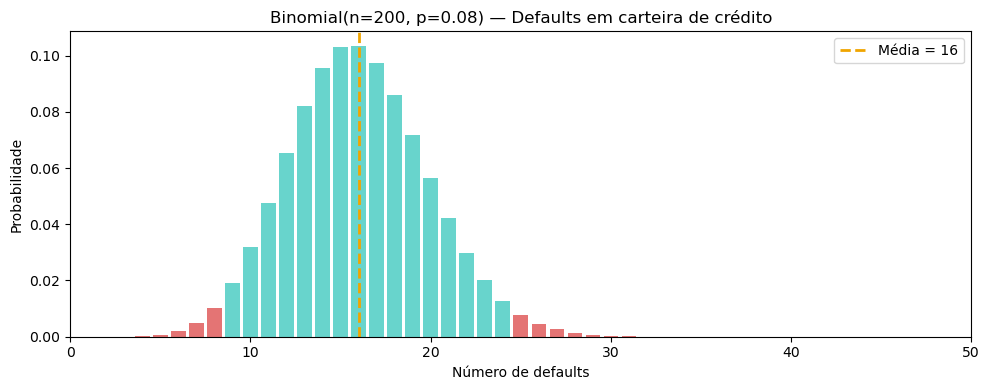

In [106]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# parâmetros — carteira de crédito
n = 200    # empréstimos aprovados
p = 0.08   # taxa histórica de default

dist = stats.binom(n, p)

print(f"Média esperada  : {dist.mean():.1f} defaults")
print(f"Desvio padrão   : {dist.std():.2f}")
print(f"\nP(exatamente 16 defaults) : {dist.pmf(16):.4f}")
print(f"P(mais de 25 defaults)    : {dist.sf(25):.4f}")
print(f"P(menos de 10 defaults)   : {dist.cdf(9):.4f}")

# intervalo que abrange 95% dos cenários
ic_low  = dist.ppf(0.025)
ic_high = dist.ppf(0.975)
print(f"\nIC 95%: entre {ic_low:.0f} e {ic_high:.0f} defaults")

# visualização
k = np.arange(0, n+1)
pmf = dist.pmf(k)

fig, ax = plt.subplots(figsize=(10, 4))
cores = ["#4ecdc4" if ic_low <= ki <= ic_high
         else "#e05c5c" for ki in k]
ax.bar(k, pmf, color=cores, width=0.8, alpha=0.85)
ax.axvline(dist.mean(), color="#f0a500", lw=2,
           linestyle="--", label=f"Média = {dist.mean():.0f}")
ax.set_xlim(0, 50)
ax.set_xlabel("Número de defaults")
ax.set_ylabel("Probabilidade")
ax.set_title(f"Binomial(n={n}, p={p}) — Defaults em carteira de crédito")
ax.legend()
plt.tight_layout()
plt.show()

In [146]:
# Probability Mass Function
# Responde: qual a probabilidade de obter exatamente 2 sucessos em 5 tentativas com p=0.1?
# É a probabilidade pontual — um valor específico de k.
stats.binom.pmf(2,n=5,p=0.1)

0.0010988481911717298

In [148]:
#Cumulative Distribution Function
# Responde: qual a probabilidade de obter até 2 sucessos em 5 tentativas com p=0.1?
# É a probabilidade acumulada — soma todas as probabilidades de k=0 até k=2.
stats.binom.cdf(2,n=5,p=0.1)

#Resultado: 0.9914 — ou seja, 99.1% de chance de sair 0, 1 ou 2 sucessos.

0.99144

In [152]:
# A relação entre as duas
# A função distribuição cumulativa é o somatório da função de massa para cada ponto observado
# cdf(2) = pmf(0) + pmf(1) + pmf(2)
p0 = stats.binom.pmf(0, n=5, p=0.1)  # P(X = 0) — nenhum sucesso
p1 = stats.binom.pmf(1, n=5, p=0.1)  # P(X = 1) — exatamente 1 sucesso
p2 = stats.binom.pmf(2, n=5, p=0.1)  # P(X = 2) — exatamente 2 sucessos
print(p0 + p1 + p2)  # → 0.99144

0.9914399999999998


In [151]:
# A média de uma distribuição normal é n x p
# Pode ser imaginado como o número de sucessos em n tentativas, onde p = probabilidade de sucesso

# A variância é n x p(1-p)

In [ ]:
# Com um n grande, e dado que p não é muito próximo nem de 0 nem de 1, a distribuição binomial pode ser aproximada pela distribuição normal

## Distribuição Chi-Quadrado

In [153]:
# medida que captura o quanto o observado se afasta do esperado — em todos os grupos ao mesmo tempo. Isso é o qui-quadrado
# Departure from expectation, a.k.a. null hypothesis or null model
# para cada categoria, você calcula a diferença entre o observado e o esperado, eleva ao quadrado, e divide pelo esperado. Soma tudo. Esse é o seu χ²
# χ² = Σ [(observado − esperado)² / esperado]
    # Por que elevar ao quadrado? Para eliminar os sinais — diferenças positivas e negativas não se cancelem
    # Por que dividir pelo esperado? Para normalizar — uma diferença de 10 num grupo de 20 é muito mais grave que uma diferença de 10 num grupo de 1.000
    # Se χ² for próximo de zero, o observado é consistente com o esperado. Se for grande, algo está errado — ou a teoria está errada, ou a máquina está com defeito, ou o dado está viciado
# Aplicações
    # Teste de aderência — os dados seguem a distribuição que eu espero?
    # Teste de independência — duas variáveis categóricas são relacionadas?

χ²      = 20.0000
p-valor = 0.000170

→ Rejeita H0: distribuição não é uniforme


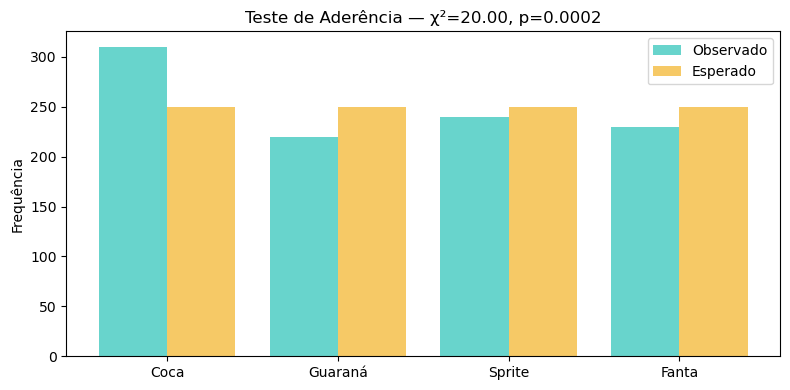

In [154]:
# Teste de aderência
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# ── Contexto: máquina de refrigerante ────────────────────
sabores  = ["Coca", "Guaraná", "Sprite", "Fanta"]
observado = np.array([310, 220, 240, 230])
esperado  = np.array([250, 250, 250, 250])   # distribuição uniforme

# ── Teste qui-quadrado ────────────────────────────────────
chi2, p_valor = stats.chisquare(observado, f_exp=esperado)

print(f"χ²      = {chi2:.4f}")
print(f"p-valor = {p_valor:.6f}")
print(f"\n→ {'Rejeita H0: distribuição não é uniforme' if p_valor < 0.05 else 'Não rejeita H0: distribuição consistente'}")

# ── Visualização ──────────────────────────────────────────
x = np.arange(len(sabores))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, observado, width=0.4,
       color="#4ecdc4", alpha=0.85, label="Observado")
ax.bar(x + 0.2, esperado,  width=0.4,
       color="#f0a500", alpha=0.6,  label="Esperado")
ax.set_xticks(x)
ax.set_xticklabels(sabores)
ax.set_ylabel("Frequência")
ax.set_title(f"Teste de Aderência — χ²={chi2:.2f}, p={p_valor:.4f}")
ax.legend()
plt.tight_layout()
plt.show()

Tabela de contingência:
         Churn  Permaneceu
Norte      210         790
Sudeste    180         820
Sul         95         905

χ²              = 52.5097
p-valor         = 0.000000
Graus liberdade = 2

→ Rejeita H0: região influencia churn


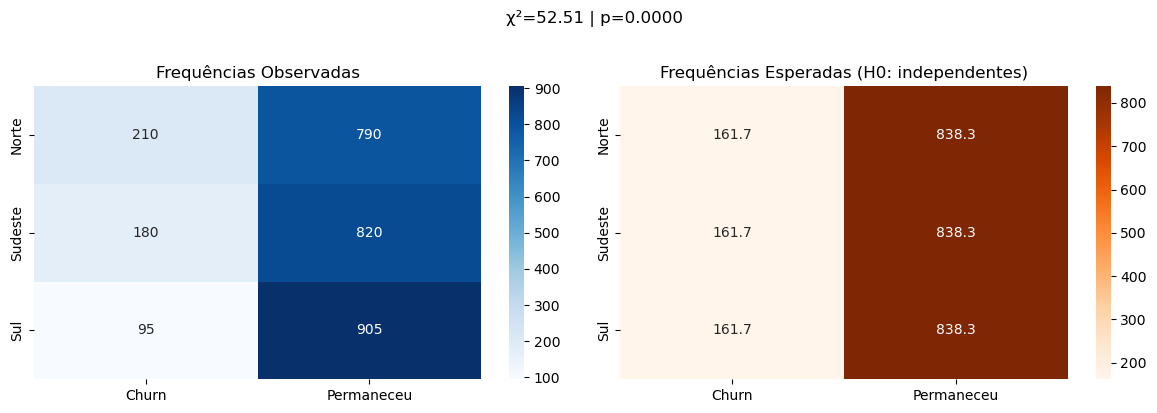

In [155]:
# Teste de independência
import pandas as pd
from scipy.stats import chi2_contingency
import seaborn as sns

# ── Contexto: região x churn ──────────────────────────────
tabela = pd.DataFrame({
    "Churn"      : [210, 180, 95],
    "Permaneceu" : [790, 820, 905]
}, index=["Norte", "Sudeste", "Sul"])

print("Tabela de contingência:")
print(tabela)

# ── Teste ─────────────────────────────────────────────────
chi2, p_valor, gl, esperado = chi2_contingency(tabela)

print(f"\nχ²              = {chi2:.4f}")
print(f"p-valor         = {p_valor:.6f}")
print(f"Graus liberdade = {gl}")
print(f"\n→ {'Rejeita H0: região influencia churn' if p_valor < 0.05 else 'Não rejeita H0: independentes'}")

# ── Heatmap observado vs esperado ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(tabela, annot=True, fmt="d",
            cmap="Blues", ax=axes[0])
axes[0].set_title("Frequências Observadas")

esp_df = pd.DataFrame(esperado.round(1),
                      index=tabela.index,
                      columns=tabela.columns)
sns.heatmap(esp_df, annot=True, fmt=".1f",
            cmap="Oranges", ax=axes[1])
axes[1].set_title("Frequências Esperadas (H0: independentes)")

plt.suptitle(f"χ²={chi2:.2f} | p={p_valor:.4f}", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Graus de liberdade#
# No teste de aderência, gl = número de categorias - 1
# No teste de aderência, gl = (linhas - 1) x (colunas - 1)

# Quanto maiores os graus de liberdade, mais para a direita a distribuição se desloca e mais difícil fica de rejeitar H0

In [ ]:
 # O qui-quadrado exige que nenhuma célula tenha frequência esperada menor que 5
# Com células muito pequenas, a aproximação qui-quadrado fica imprecisa. Se isso acontecer, você agrega categorias ou usa o Teste Exato de Fisher

## Distribuição F

In [156]:
# Nasce da razão entre duas variâncias
# Se tenho dois grupos e quero saber se eles têm a mesma variabilidade, ou se um modelo explica mais variância do que o acaso esperaria, calcula-se esta razão e compara-se com a distribuição F
# A distribuição F diz qual razão é esperada por acaso, e o teste F diz se o observado é plausível
# Onde F aparece na prática: ANOVA, regressão linear, comparação de variâncias

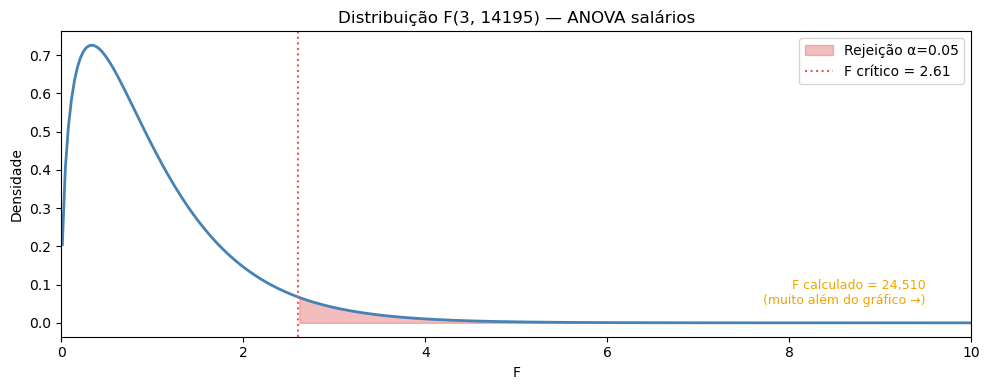

In [161]:
x = np.linspace(0.01, 10, 300)
pdf = stats.f.pdf(x, dfn=k-1, dfd=n_total-k)
f_crit = stats.f.ppf(0.95, dfn=k-1, dfd=n_total-k)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, pdf, color="steelblue", lw=2)

# região de rejeição
ax.fill_between(x, pdf, where=(x >= f_crit),
                color="#e05c5c", alpha=0.4, label=f"Rejeição α=0.05")

# F crítico
ax.axvline(f_crit, color="#e05c5c", lw=1.5,
           linestyle=":", label=f"F crítico = {f_crit:.2f}")

# F calculado está fora do gráfico — anota com seta
ax.annotate(f"F calculado = {F_stat:,.0f}\n(muito além do gráfico →)",
            xy=(9.5, 0.05), fontsize=9,
            color="#f0a500", ha="right",
            arrowprops=None)

ax.set_xlim(0, 10)
ax.set_xlabel("F")
ax.set_ylabel("Densidade")
ax.set_title(f"Distribuição F({k-1}, {n_total-k}) — ANOVA salários")
ax.legend()
plt.tight_layout()
plt.show()

Q1 = $104,000 | Q2 = $142,000 | Q3 = $185,900

Grupo                       n        Média           DP      Mediana
-------------------------------------------------------------------
Iniciante (mín→Q1)       3589 $    75,239 $    19,875 $    79,000
Júnior (Q1→Q2)           3529 $   124,206 $    11,339 $   125,000
Pleno (Q2→Q3)            3544 $   163,217 $    13,040 $   162,000
Sênior (Q3→máx)          3537 $   236,233 $    44,647 $   224,400

ANOVA — jobs_in_data_2024 | salary_in_usd
F-statistic          :   24510.0856
p-valor              :     0.00e+00
───────────────────────────────────────────────────────
SQ Entre grupos      : $  49,324,258,970,153  (gl=3)
SQ Dentro dos grupos : $   9,522,037,422,158  (gl=14195)
MQ Entre             : $  16,441,419,656,718
MQ Dentro            : $         670,802,214
F manual             :   24510.0856

Interpretação:
  F=24510.1 → variância ENTRE grupos é 24510x
  maior que a variância DENTRO dos grupos.
  p=0.00e+00 → rejeitamos H0 com qualque

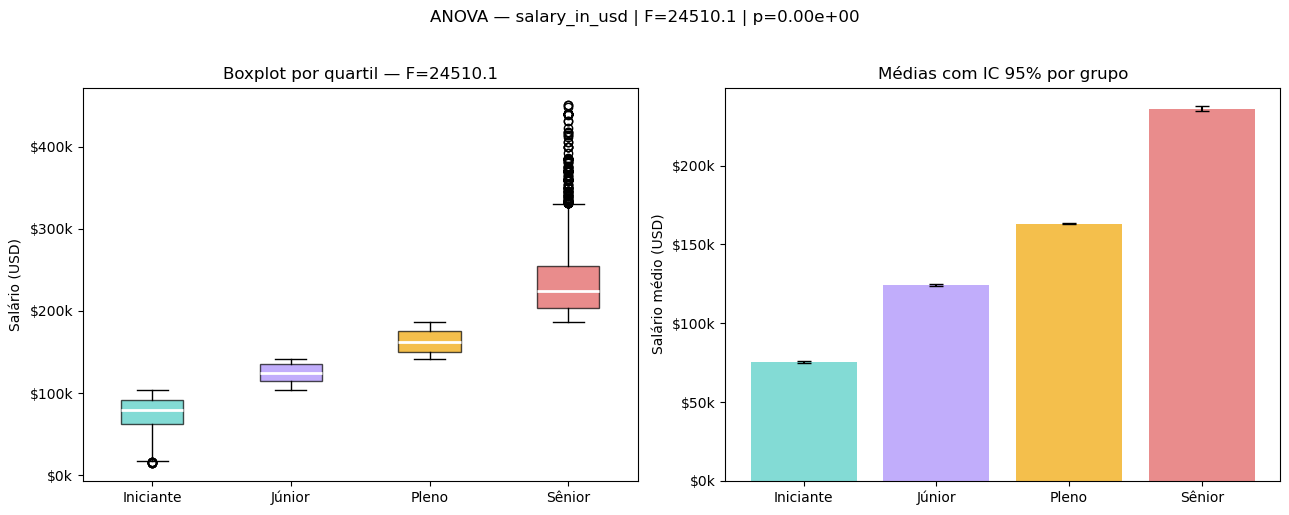

In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ── Calcula quartis ───────────────────────────────────────
q1 = jobs["salary_in_usd"].quantile(0.25)
q2 = jobs["salary_in_usd"].quantile(0.50)
q3 = jobs["salary_in_usd"].quantile(0.75)

print(f"Q1 = ${q1:,.0f} | Q2 = ${q2:,.0f} | Q3 = ${q3:,.0f}")

# ── Grupos ────────────────────────────────────────────────
g1 = jobs.loc[jobs["salary_in_usd"] <= q1,                          "salary_in_usd"]
g2 = jobs.loc[(jobs["salary_in_usd"] > q1) & (jobs["salary_in_usd"] <= q2), "salary_in_usd"]
g3 = jobs.loc[(jobs["salary_in_usd"] > q2) & (jobs["salary_in_usd"] <= q3), "salary_in_usd"]
g4 = jobs.loc[jobs["salary_in_usd"] > q3,                           "salary_in_usd"]

grupos = [g1, g2, g3, g4]
nomes  = ["Iniciante (mín→Q1)", "Júnior (Q1→Q2)",
          "Pleno (Q2→Q3)",      "Sênior (Q3→máx)"]

# ── Estatísticas descritivas ──────────────────────────────
print(f"\n{'Grupo':<22} {'n':>6} {'Média':>12} {'DP':>12} {'Mediana':>12}")
print("-" * 67)
for nome, g in zip(nomes, grupos):
    print(f"{nome:<22} {len(g):>6} ${g.mean():>10,.0f} "
          f"${g.std():>10,.0f} ${g.median():>10,.0f}")

# ── ANOVA ─────────────────────────────────────────────────
k       = len(grupos)
n_total = sum(len(g) for g in grupos)
F_stat, p_valor = stats.f_oneway(*grupos)

media_geral = np.concatenate(grupos).mean()
sqe = sum(len(g) * (g.mean() - media_geral)**2 for g in grupos)
sqr = sum(((g - g.mean())**2).sum()             for g in grupos)
mse = sqe / (k - 1)
msr = sqr / (n_total - k)

print(f"\n{'='*55}")
print(f"ANOVA — jobs_in_data_2024 | salary_in_usd")
print(f"{'='*55}")
print(f"F-statistic          : {F_stat:>12.4f}")
print(f"p-valor              : {p_valor:>12.2e}")
print(f"{'─'*55}")
print(f"SQ Entre grupos      : ${sqe:>20,.0f}  (gl={k-1})")
print(f"SQ Dentro dos grupos : ${sqr:>20,.0f}  (gl={n_total-k})")
print(f"MQ Entre             : ${mse:>20,.0f}")
print(f"MQ Dentro            : ${msr:>20,.0f}")
print(f"F manual             : {mse/msr:>12.4f}")
print(f"{'='*55}")
print(f"\nInterpretação:")
print(f"  F={F_stat:.1f} → variância ENTRE grupos é {F_stat:.0f}x")
print(f"  maior que a variância DENTRO dos grupos.")
print(f"  p={p_valor:.2e} → rejeitamos H0 com qualquer α razoável.")
print(f"  Conclusão: as médias salariais dos 4 grupos")
print(f"  são estatisticamente diferentes entre si.")

# ── Plot ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cores_box = ["#4ecdc4","#a78bfa","#f0a500","#e05c5c"]

bp = axes[0].boxplot(grupos, labels=[n.split(" ")[0] for n in nomes],
                     patch_artist=True,
                     medianprops=dict(color="white", lw=2))
for patch, cor in zip(bp["boxes"], cores_box):
    patch.set_facecolor(cor)
    patch.set_alpha(0.7)
axes[0].set_ylabel("Salário (USD)")
axes[0].set_title(f"Boxplot por quartil — F={F_stat:.1f}")
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))

medias = [g.mean() for g in grupos]
ics    = [stats.t.ppf(0.975, len(g)-1) * g.std() / np.sqrt(len(g))
          for g in grupos]
x = np.arange(k)
axes[1].bar(x, medias, color=cores_box, alpha=0.7,
            yerr=ics, capsize=5,
            error_kw={"color":"#333","lw":1.5})
axes[1].set_xticks(x)
axes[1].set_xticklabels([n.split(" ")[0] for n in nomes])
axes[1].set_ylabel("Salário médio (USD)")
axes[1].set_title("Médias com IC 95% por grupo")
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))

plt.suptitle(f"ANOVA — salary_in_usd | F={F_stat:.1f} | p={p_valor:.2e}",
             y=1.02)
plt.tight_layout()
plt.show()

In [163]:
from scipy.stats import levene
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd

# ── Teste de Levene — homocedasticidade ───────────────────
stat_lev, p_lev = levene(*grupos)
print(f"Levene: estatística={stat_lev:.4f}, p={p_lev:.2e}")
print(f"→ {'Variâncias heterogêneas' if p_lev < 0.05 else 'Variâncias homogêneas'}")

# ── Tukey HSD — quais pares diferem? ─────────────────────
todos_salarios = np.concatenate(grupos)
todos_grupos   = np.concatenate([
    [nome]*len(g) for nome, g in zip(
        ["Iniciante","Júnior","Pleno","Sênior"], grupos)
])

tukey = pairwise_tukeyhsd(todos_salarios, todos_grupos, alpha=0.05)
print(f"\n{tukey}")

Levene: estatística=1163.8863, p=0.00e+00
→ Variâncias heterogêneas

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1  group2   meandiff  p-adj    lower       upper    reject
-----------------------------------------------------------------
Iniciante Júnior   48966.897   0.0  47389.3418  50544.4523   True
Iniciante  Pleno  87978.1183   0.0  86402.2472  89553.9894   True
Iniciante Sênior 160993.8063   0.0 159417.1508 162570.4618   True
   Júnior  Pleno  39011.2213   0.0  37428.7082  40593.7343   True
   Júnior Sênior 112026.9093   0.0 110443.6151 113610.2034   True
    Pleno Sênior   73015.688   0.0  71434.0719  74597.3041   True
-----------------------------------------------------------------


## Distrubição Poisson, Exponencial e Weilbull

In [164]:
# Palavras-chave
# Lambda - taxa (por unidade de tempo ou espaço) em que eventos ocorrem
# Distribuição de Poisson - distribuição de frequência do número de eventos amostrados em unidades de tempo ou espaço
# Distribuição Exponencial - distribuição de frequência (tempo ou espaço) de um evento para o próximo
# Distribuição Weibull - versão generalizada da distribuição exponencial em que a taxa do evento pode AUMENTAR ou DIMINUIR com o tempo (ex: risco de falha de um equipamento aumenta com o envelhecimento)

In [165]:
# Distribuição de Poisson
# Dado que eventos ocorrem a uma taxa média λ por unidade de tempo ou espaço, qual a probabilidade de observar exatamente k eventos nessa unidade?
# O parâmetro λ (lambda) é ao mesmo tempo a média e a variância da distribuição — isso se chama equidispersão
# É a propriedade diagnóstica mais importante: se nos seus dados a variância for muito maior que a média, a Poisson não se aplica e você precisa da Binomial Negativa
# Pressupostos
    # Independência — um evento não influencia a probabilidade do próximo. O gol do minuto 30 não afeta a probabilidade de gol no minuto 60
    # Taxa constante — λ é estável no período observado. Chegadas de clientes num horário de pico violam isso — λ muda ao longo do dia
    # Raridade relativa — os eventos são suficientemente raros para que dois não ocorram simultaneamente. Na prática isso é quase sempre satisfeito.


Gols/jogo | Observado | Esperado | Diferença
------------------------------------------------
    0     |      24   |    25.5  |    -1.5
    1     |      81   |    69.0  |   +12.0
    2     |      87   |    93.1  |    -6.1
    3     |      79   |    83.8  |    -4.8
    4     |      49   |    56.5  |    -7.5
    5     |      41   |    30.5  |   +10.5
    6     |      14   |    13.7  |    +0.3
    7     |       2   |     5.3  |    -3.3
    8     |       3   |     1.8  |    +1.2

Média amostral    : 2.6711  (λ real = 2.7)
Variância amostral: 2.7155
Razão Var/Média   : 1.0166
→ Equidispersão OK — Poisson adequada

Perguntas sobre λ=2.7:
P(0 gols)        = 0.0672  (6.7%)
P(1 gol)         = 0.1815  (18.1%)
P(2 gols)        = 0.2450  (24.5%)
P(> 4 gols)      = 0.1371  (13.7%)
P(entre 2 e 4)   = 0.6142  (61.4%)

Teste de aderência à Poisson:
χ² = 8.0646  |  p = 0.3269
→ Dados consistentes com Poisson(λ=2.7)

λ estimado por MLE : 2.6711  (= média amostral)


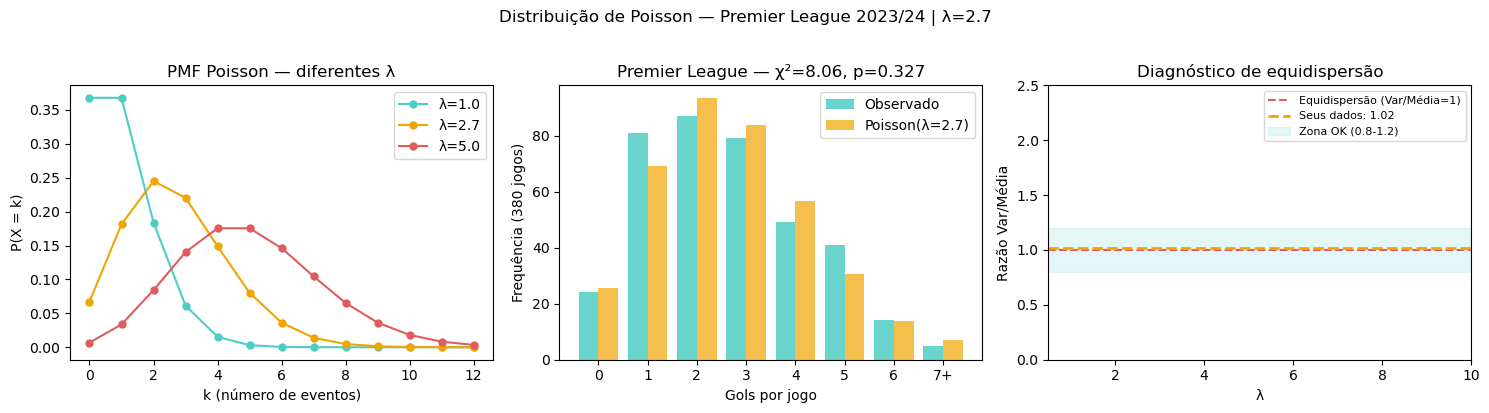

In [169]:
# exemplo
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# ── Dataset: gols por partida — Premier League 2023/24 ────
# 380 partidas, distribuição real aproximada
np.random.seed(42)

# λ histórico da Premier League ≈ 2.7 gols/jogo
lam_real = 2.7
dist_pois = stats.poisson(lam_real)

# simula temporada
gols_obs_raw = dist_pois.rvs(380)
freq_obs = np.bincount(gols_obs_raw, minlength=9)[:9]
k_vals   = np.arange(9)
freq_esp = dist_pois.pmf(k_vals) * 380

print("Gols/jogo | Observado | Esperado | Diferença")
print("-" * 48)
for k, obs, esp in zip(k_vals, freq_obs, freq_esp):
    print(f"    {k}     |    {obs:>4}   |  {esp:>6.1f}  |  {obs-esp:>+6.1f}")

# ── Estatísticas da amostra ───────────────────────────────
media_obs = gols_obs_raw.mean()
var_obs   = gols_obs_raw.var()
razao     = var_obs / media_obs

print(f"\nMédia amostral    : {media_obs:.4f}  (λ real = {lam_real})")
print(f"Variância amostral: {var_obs:.4f}")
print(f"Razão Var/Média   : {razao:.4f}")
print(f"→ {'Equidispersão OK — Poisson adequada' if 0.8 <= razao <= 1.2 else 'Overdispersion — considere Binomial Negativa'}")

# ── Perguntas de negócio ──────────────────────────────────
p_entre = dist_pois.cdf(4) - dist_pois.cdf(1)

print(f"\nPerguntas sobre λ={lam_real}:")
print(f"P(0 gols)        = {dist_pois.pmf(0):.4f}  ({dist_pois.pmf(0)*100:.1f}%)")
print(f"P(1 gol)         = {dist_pois.pmf(1):.4f}  ({dist_pois.pmf(1)*100:.1f}%)")
print(f"P(2 gols)        = {dist_pois.pmf(2):.4f}  ({dist_pois.pmf(2)*100:.1f}%)")
print(f"P(> 4 gols)      = {dist_pois.sf(4):.4f}  ({dist_pois.sf(4)*100:.1f}%)")
print(f"P(entre 2 e 4)   = {p_entre:.4f}  ({p_entre*100:.1f}%)")

# ── Teste de aderência qui-quadrado ───────────────────────
obs_agrup = np.append(freq_obs[:7], freq_obs[7:].sum())
esp_agrup = np.append(freq_esp[:7], freq_esp[7:].sum())

# normaliza esperado para soma idêntica ao observado
esp_agrup = esp_agrup * (obs_agrup.sum() / esp_agrup.sum())

chi2_stat, p_chi2 = stats.chisquare(obs_agrup, f_exp=esp_agrup)
print(f"\nTeste de aderência à Poisson:")
print(f"χ² = {chi2_stat:.4f}  |  p = {p_chi2:.4f}")
print(f"→ {'Aderência rejeitada' if p_chi2 < 0.05 else 'Dados consistentes com Poisson(λ=2.7)'}")

# ── Estimação do λ por MLE ────────────────────────────────
lam_mle = gols_obs_raw.mean()
print(f"\nλ estimado por MLE : {lam_mle:.4f}  (= média amostral)")

# ── Visualização ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# PMF com diferentes λ
k_plot = np.arange(0, 13)
for lam, cor in [(1.0,"#4ecdc4"),(2.7,"#f0a500"),(5.0,"#e05c5c")]:
    axes[0].plot(k_plot, stats.poisson(lam).pmf(k_plot),
                 "o-", color=cor, lw=1.5, ms=5, label=f"λ={lam}")
axes[0].set_xlabel("k (número de eventos)")
axes[0].set_ylabel("P(X = k)")
axes[0].set_title("PMF Poisson — diferentes λ")
axes[0].legend()

# observado vs esperado
x = np.arange(len(obs_agrup))
labels = [str(i) for i in range(7)] + ["7+"]
axes[1].bar(x - 0.2, obs_agrup, width=0.4,
            color="#4ecdc4", alpha=0.85, label="Observado")
axes[1].bar(x + 0.2, esp_agrup, width=0.4,
            color="#f0a500", alpha=0.7,  label=f"Poisson(λ={lam_real})")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_xlabel("Gols por jogo")
axes[1].set_ylabel("Frequência (380 jogos)")
axes[1].set_title(f"Premier League — χ²={chi2_stat:.2f}, p={p_chi2:.3f}")
axes[1].legend()

# razão Var/Média para diagnóstico
lambdas = np.linspace(0.5, 10, 100)
axes[2].axhline(1, color="#e05c5c", lw=1.5,
                linestyle="--", label="Equidispersão (Var/Média=1)")
axes[2].axhline(razao, color="#f0a500", lw=2,
                linestyle="--", label=f"Seus dados: {razao:.2f}")
axes[2].fill_between(lambdas, 0.8, 1.2,
                     color="#4ecdc4", alpha=0.15, label="Zona OK (0.8-1.2)")
axes[2].set_xlim(0.5, 10)
axes[2].set_ylim(0, 2.5)
axes[2].set_xlabel("λ")
axes[2].set_ylabel("Razão Var/Média")
axes[2].set_title("Diagnóstico de equidispersão")
axes[2].legend(fontsize=8)

plt.suptitle(f"Distribuição de Poisson — Premier League 2023/24 | λ={lam_real}",
             y=1.02)
plt.tight_layout()
plt.show()

# O que o código entrega:
# Tabela comparando frequências observadas vs esperadas pela Poisson — o teste visual de aderência.
# Diagnóstico de equidispersão — razão Var/Média próxima de 1 confirma que Poisson é adequada.
# Perguntas de negócio respondidas — probabilidade de 0 gols, mais de 4 gols, entre 2 e 4.
# Teste de aderência qui-quadrado formal — confirma ou rejeita que os dados seguem Poisson.
# Três gráficos — PMF com diferentes λ, observado vs esperado, e diagnóstico visual de equidispersão.

In [170]:
# Distribuição Exponencial
# Complemento da Poisson — modela o TEMPO entre eventos
# Parâmetro: λ (taxa) ou equivalentemente escala = 1/λ
# Propriedade-chave: ausência de memória
# P(T > t+s | T > s) = P(T > t) — não importa quanto tempo já esperou
# Média = 1/λ | Variância = 1/λ²
# Uso: tempo entre chegadas, tempo até falha (taxa constante), tempo entre transações de fraude

Distribuição Exponencial — tempo entre chamadas:
λ (taxa)          : 6 chamadas/hora
Média esperada    : 10.0 minutos
Média observada   : 10.0 minutos

P(próxima chamada em < 5 min)  : 0.3935
P(espera > 20 min)             : 0.1353
P(entre 5 e 15 min)            : 0.3834


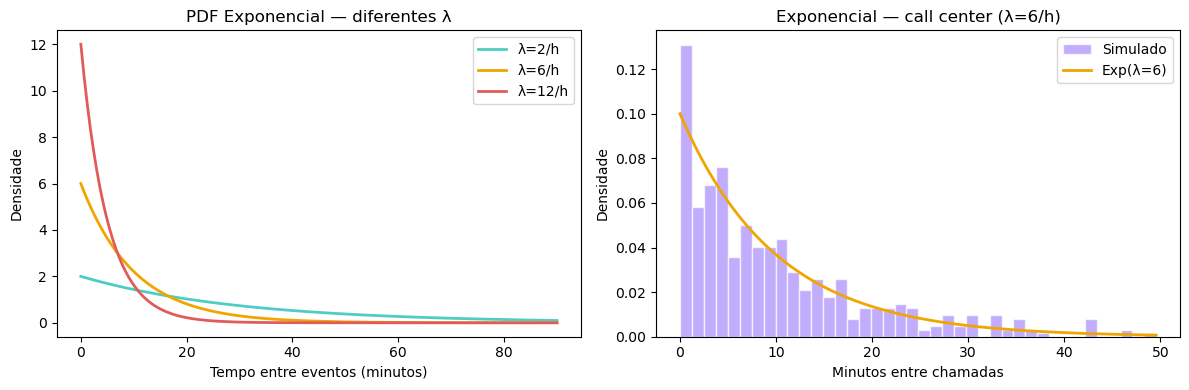

In [174]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ── Contexto: tempo entre chamadas num call center ────────
# λ = 6 chamadas/hora → tempo médio entre chamadas = 10 min
lam   = 6
escala = 1 / lam          # scipy usa escala = 1/λ
dist_exp = stats.expon(scale=escala)

np.random.seed(42)
tempos = dist_exp.rvs(500)   # 500 intervalos simulados

print("Distribuição Exponencial — tempo entre chamadas:")
print(f"λ (taxa)          : {lam} chamadas/hora")
print(f"Média esperada    : {dist_exp.mean()*60:.1f} minutos")
print(f"Média observada   : {tempos.mean()*60:.1f} minutos")
print(f"\nP(próxima chamada em < 5 min)  : {dist_exp.cdf(5/60):.4f}")
print(f"P(espera > 20 min)             : {dist_exp.sf(20/60):.4f}")
print(f"P(entre 5 e 15 min)            : {dist_exp.cdf(15/60)-dist_exp.cdf(5/60):.4f}")

# ── Plot ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x = np.linspace(0, 1.5, 300)
for lam_p, cor in [(2,"#4ecdc4"),(6,"#f0a500"),(12,"#e05c5c")]:
    axes[0].plot(x*60, stats.expon(scale=1/lam_p).pdf(x),
                 color=cor, lw=2, label=f"λ={lam_p}/h")
axes[0].set_xlabel("Tempo entre eventos (minutos)")
axes[0].set_ylabel("Densidade")
axes[0].set_title("PDF Exponencial — diferentes λ")
axes[0].legend()

axes[1].hist(tempos * 60, bins=40, density=True,
             color="#a78bfa", alpha=0.7, edgecolor="white",
             label="Simulado")
x2 = np.linspace(0, tempos.max() * 60, 300)
axes[1].plot(x2, dist_exp.pdf(x2 / 60) / 60,
             color="#f0a500", lw=2, label=f"Exp(λ={lam})")
axes[1].set_xlabel("Minutos entre chamadas")
axes[1].set_ylabel("Densidade")
axes[1].set_title("Exponencial — call center (λ=6/h)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [175]:
# Distribuição Weibull
# Generalização da Exponencial com taxa de falha variável no tempo
# Parâmetros: forma (β) e escala (η)
# β < 1 → taxa decrescente (burn-in, mortalidade infantil)
# β = 1 → taxa constante   (= Exponencial)
# β > 1 → taxa crescente   (envelhecimento, desgaste)
# Uso: confiabilidade de equipamentos, análise de sobrevivência, tempo até churn, tempo de vida útil de produtos

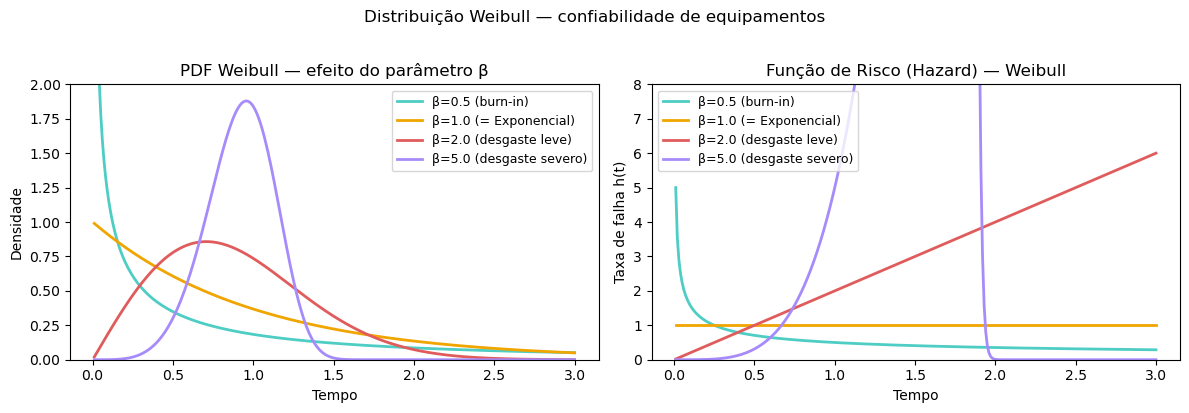

Weibull — vida útil de equipamentos (β=2.5, η=1000h):
Média esperada     : 887 horas
Mediana esperada   : 864 horas
P(falha < 500h)    : 0.1620  (16.2%)
P(vida > 1200h)    : 0.2065  (20.7%)
Garantia 10% falha : 407 horas


In [173]:
# ── Contexto: tempo de vida útil de equipamentos ──────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x = np.linspace(0.01, 3, 300)

# PDF — efeito do parâmetro de forma β
betas = [(0.5, "#4ecdc4", "β=0.5 (burn-in)"),
         (1.0, "#f0a500", "β=1.0 (= Exponencial)"),
         (2.0, "#e05c5c", "β=2.0 (desgaste leve)"),
         (5.0, "#a78bfa", "β=5.0 (desgaste severo)")]

for beta, cor, label in betas:
    axes[0].plot(x, stats.weibull_min(beta, scale=1).pdf(x),
                 color=cor, lw=2, label=label)
axes[0].set_xlabel("Tempo")
axes[0].set_ylabel("Densidade")
axes[0].set_title("PDF Weibull — efeito do parâmetro β")
axes[0].set_ylim(0, 2)
axes[0].legend(fontsize=9)

# Taxa de falha (hazard function) — o que diferencia da Exponencial
for beta, cor, label in betas:
    pdf = stats.weibull_min(beta, scale=1).pdf(x)
    sf  = stats.weibull_min(beta, scale=1).sf(x)
    hazard = pdf / (sf + 1e-10)
    axes[1].plot(x, hazard, color=cor, lw=2, label=label)
axes[1].set_xlabel("Tempo")
axes[1].set_ylabel("Taxa de falha h(t)")
axes[1].set_title("Função de Risco (Hazard) — Weibull")
axes[1].set_ylim(0, 8)
axes[1].legend(fontsize=9)

plt.suptitle("Distribuição Weibull — confiabilidade de equipamentos",
             y=1.02)
plt.tight_layout()
plt.show()

# ── Aplicação: estima vida útil de equipamentos ───────────
np.random.seed(42)
beta_eq, escala_eq = 2.5, 1000   # equipamento com desgaste
dist_wb = stats.weibull_min(beta_eq, scale=escala_eq)
vida_util = dist_wb.rvs(200)

print("Weibull — vida útil de equipamentos (β=2.5, η=1000h):")
print(f"Média esperada     : {dist_wb.mean():.0f} horas")
print(f"Mediana esperada   : {dist_wb.median():.0f} horas")
print(f"P(falha < 500h)    : {dist_wb.cdf(500):.4f}  ({dist_wb.cdf(500)*100:.1f}%)")
print(f"P(vida > 1200h)    : {dist_wb.sf(1200):.4f}  ({dist_wb.sf(1200)*100:.1f}%)")
print(f"Garantia 10% falha : {dist_wb.ppf(0.10):.0f} horas")

## FIM